In [82]:
import sys
sys.path.append("..")

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [84]:
df_ch_przeplyw = pd.read_parquet('../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../data/processed/Chorzów/energia.parquet')
df_ch_opady = pd.read_parquet('../data/processed/Chorzów/suma_opadow.parquet')

### LightGBM
Model ma się uczyć zależności między ilością przepompowanych ścieków, a opadami atmosferycznymi.
Nie tylko przewidywanie pompowania na podstawie poprzednich godzin, ale uwzględnienie jak to reagowało na deszcz

CEL: Wykrywanie sytuacji, w których ilość przepompowanych ścieków jest większa niż powinna być przy danych warunkach opadowych - czy powinniśmy się spodziewać aż tak dużej ilości ścieków?

LightGBM - ma wyznaczać oczekiwane pompowanie (na podtsaiwe historycznej zależności między opadami, porą dnia, ilością ścieków) i
ma wykrywać nadwyżki względem pogody

In [85]:
df = df_ch_scieki.copy()

df["Sposób_pomiaru"] = df["Sposób_pomiaru"].astype(str).str.strip()
df = df[df["Sposób_pomiaru"] == "Wartość z pomiaru"].copy()


if "Data_czas" in df.columns:
    df["Data_czas"] = pd.to_datetime(df["Data_czas"])
    df = df.set_index("Data_czas")

df = df.rename(columns={"Ilosc_przepompowanych_sciekow": "ilosc"})

# konwersja na liczbowe
df["ilosc"] = pd.to_numeric(
    df["ilosc"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

# usuwanie zer i śmieci
df = df[df["ilosc"].notna()]
print(df[["ilosc"]].head(10))

                         ilosc
Data_czas                     
2024-10-13 00:00:00  4891880.0
2024-10-13 00:00:54  4891880.0
2024-10-13 00:01:06  4891880.0
2024-10-13 00:01:18  4891890.0
2024-10-13 00:01:26  4891890.0
2024-10-13 00:01:52  4891890.0
2024-10-13 00:14:04  4891890.0
2024-10-13 00:14:20  4891890.0
2024-10-13 00:14:34  4891890.0
2024-10-13 00:14:44  4891890.0


In [86]:
# Mamy zduplikowane daty (najprawdopodobniej wynikają ze zmiany czasu na zimowy/letni), więc zachowamy te największe odczyty dla każdej daty
df = df.groupby(level=0).agg({"ilosc": "max"})
df = df.sort_index()

df.head()


,ilosc
Data_czas,
2024-10-13 00:00:00,4891880.0
2024-10-13 00:00:54,4891880.0
2024-10-13 00:01:06,4891880.0
2024-10-13 00:01:18,4891890.0
2024-10-13 00:01:26,4891890.0


In [87]:
df_ch_opady["Data_czas"] = pd.to_datetime(df_ch_opady["Data_czas"])
df_ch_opady = df_ch_opady.set_index("Data_czas").sort_index()

print(df_ch_opady.head())

                     suma_opadu_mm
Data_czas                         
2024-01-01 00:00:00            0.0
2024-01-01 01:00:00            0.0
2024-01-01 02:00:00            0.0
2024-01-01 03:00:00            0.0
2024-01-01 04:00:00            0.0


In [88]:
hourly = df["ilosc"].resample("1h").last()
df_1h = pd.DataFrame({"przepompowano": hourly.diff()})

#reset licznika 
df_1h.loc[df_1h["przepompowano"] < 0, "przepompowano"] = np.nan

df_lgbm = df_1h.join(df_ch_opady[["suma_opadu_mm"]], how="left")
df_lgbm["suma_opadu_mm"] = df_lgbm["suma_opadu_mm"].fillna(0)

print(df_lgbm.head(10))

                     przepompowano  suma_opadu_mm
Data_czas                                        
2024-10-13 00:00:00            NaN            0.0
2024-10-13 01:00:00           10.0            0.0
2024-10-13 02:00:00           20.0            0.0
2024-10-13 03:00:00           10.0            0.0
2024-10-13 04:00:00           20.0            0.0
2024-10-13 05:00:00           10.0            0.0
2024-10-13 06:00:00           20.0            0.0
2024-10-13 07:00:00           10.0            0.0
2024-10-13 08:00:00           30.0            0.0
2024-10-13 09:00:00           20.0            0.0


In [89]:
#Dajemy modelowi kontekst kalendarzowy, ponieważ może zależeć od pory dnia i dnia tygodnia
df_lgbm["hour"] = df_lgbm.index.hour
df_lgbm["dayofweek"] = df_lgbm.index.day_of_week

print(df_lgbm.head(10))

                     przepompowano  suma_opadu_mm  hour  dayofweek
Data_czas                                                         
2024-10-13 00:00:00            NaN            0.0     0          6
2024-10-13 01:00:00           10.0            0.0     1          6
2024-10-13 02:00:00           20.0            0.0     2          6
2024-10-13 03:00:00           10.0            0.0     3          6
2024-10-13 04:00:00           20.0            0.0     4          6
2024-10-13 05:00:00           10.0            0.0     5          6
2024-10-13 06:00:00           20.0            0.0     6          6
2024-10-13 07:00:00           10.0            0.0     7          6
2024-10-13 08:00:00           30.0            0.0     8          6
2024-10-13 09:00:00           20.0            0.0     9          6


In [90]:
r = df_lgbm["suma_opadu_mm"]

df_lgbm["opad_0h"] = r                      # bieżąca godzina

for k in [2, 3, 6, 12, 24, 48, 72, 168]:
    df_lgbm[f"opad_{k}h"] = r.rolling(k).sum()
    
df_lgbm["opad_max3h"] = r.rolling(3).max()   # intensywność szczytowa

last_rain = df_lgbm.index.to_series().where(r > 0.1).ffill()
df_lgbm["h_od_deszczu"] = ((df_lgbm.index.to_series() - last_rain)
                           .dt.total_seconds() / 3600).clip(upper=240)

print(df_lgbm.head())

                     przepompowano  suma_opadu_mm  hour  dayofweek  opad_0h  \
Data_czas                                                                     
2024-10-13 00:00:00            NaN            0.0     0          6      0.0   
2024-10-13 01:00:00           10.0            0.0     1          6      0.0   
2024-10-13 02:00:00           20.0            0.0     2          6      0.0   
2024-10-13 03:00:00           10.0            0.0     3          6      0.0   
2024-10-13 04:00:00           20.0            0.0     4          6      0.0   

                     opad_2h  opad_3h  opad_6h  opad_12h  opad_24h  opad_48h  \
Data_czas                                                                      
2024-10-13 00:00:00      NaN      NaN      NaN       NaN       NaN       NaN   
2024-10-13 01:00:00      0.0      NaN      NaN       NaN       NaN       NaN   
2024-10-13 02:00:00      0.0      0.0      NaN       NaN       NaN       NaN   
2024-10-13 03:00:00      0.0      0.0      NaN

In [91]:
features = [
    "hour", "dayofweek",
    "opad_0h", "opad_2h", "opad_3h", "opad_6h", "opad_12h",
    "opad_24h", "opad_48h", "opad_72h", "opad_168h",
    "opad_max3h", "h_od_deszczu"
]

X = df_lgbm[features].copy()
y = df_lgbm["przepompowano"].copy()

print("Liczba cech:", X.shape[1])
print("Liczba obserwacji:", len(X))

print("\nBraki w cechach:", X.isna().sum())
print("\nBraki w y:", y.isna().sum())

Liczba cech: 13
Liczba obserwacji: 17523

Braki w cechach: hour              0
dayofweek         0
opad_0h           0
opad_2h           1
opad_3h           2
opad_6h           5
opad_12h         11
opad_24h         23
opad_48h         47
opad_72h         71
opad_168h       167
opad_max3h        2
h_od_deszczu     12
dtype: int64

Braki w y: 5


In [92]:
# Usuwamy tylko wiersze z brakującą wartością docelową
valid_idx = y.notna()

X = X.loc[valid_idx].copy()
y = y.loc[valid_idx].copy()

train_end = int(len(X)*0.7)
val_end = int(len(X)*0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

TRAIN: (12262, 13) 2024-10-13 01:00:00 2026-03-07 22:00:00
VAL: (2628, 13) 2026-03-07 23:00:00 2026-06-25 12:00:00
TEST: (2628, 13) 2026-06-25 13:00:00 2026-10-13 00:00:00


In [93]:
# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [94]:
y_pred_val = lgbm.predict(X_val)
q_val = lgbm_q.predict(X_val)

prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))

MAE modelu:   8.24
MAE baseline: 8.73


Godziny ponad normę: 89 z 2628


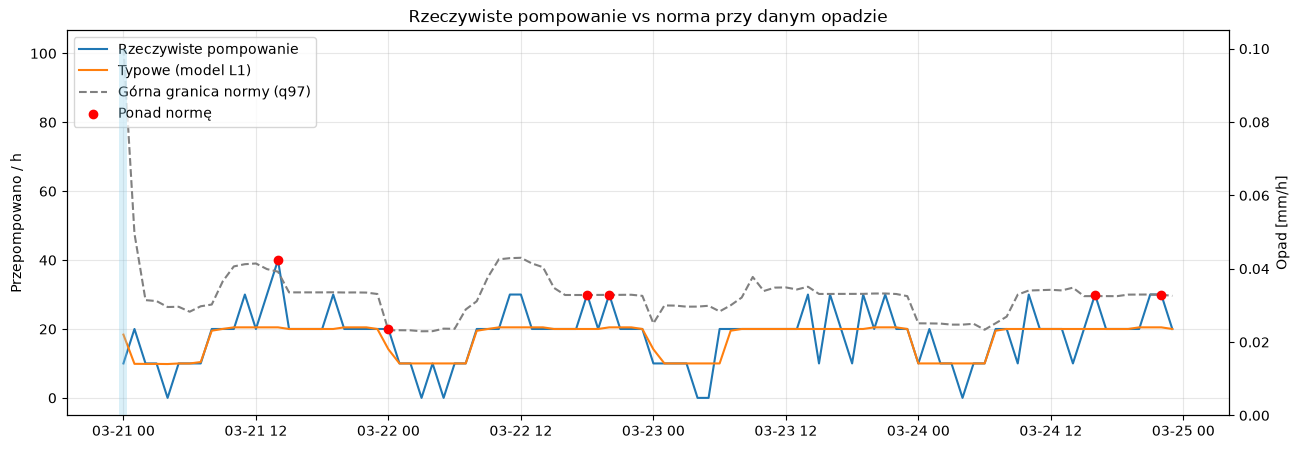

In [95]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [96]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 27
Alarmy skumulowane: 50


In [97]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_val)
q_val = cb_q97.predict(X_val)

print("Odsetek przekroczeń Q97 (CatBoost):", round((y_val > q_val).mean() * 100, 2), "%")

Odsetek przekroczeń Q97 (CatBoost): 1.94 %


Godziny ponad normę: 51 z 2628


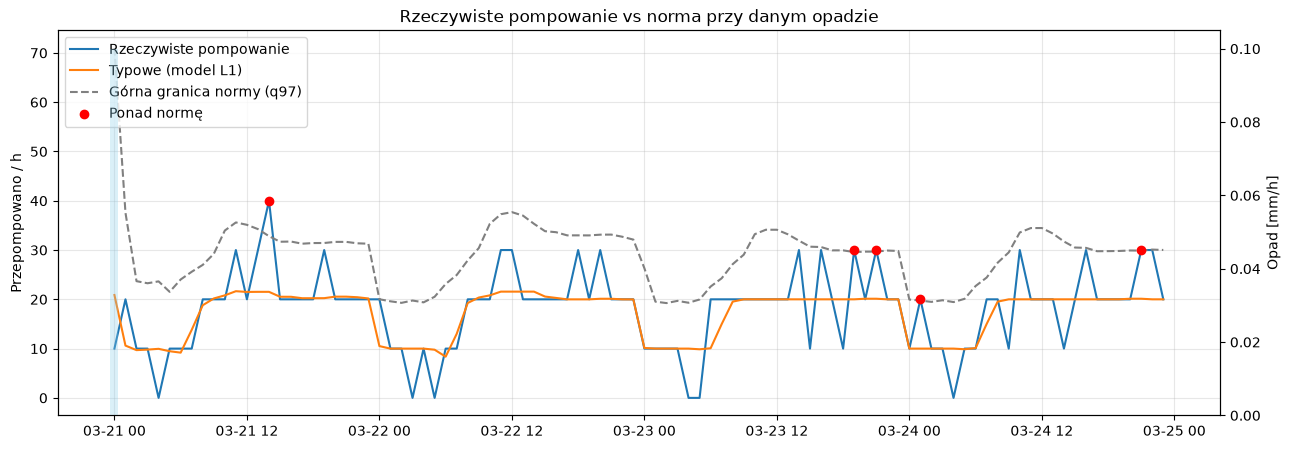

In [98]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [99]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 18
Alarmy skumulowane: 38
